# Food_Delivery_Time__Prediction

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
# 1. Load the Dataset
df = pd.read_csv("Food_Delivery_Times.csv")
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [3]:

# 2. Drop unique identifiers that hold no predictive value
df.drop(['Order_ID','Preparation_Time_min'], axis=1, inplace=True)

# 3. Impute Missing Values
# Use median for the numeric column to avoid outlier skew
df['Courier_Experience_yrs'].fillna(df['Courier_Experience_yrs'].median(), inplace=True)

# Use mode (most frequent value) for categorical columns
for col in ['Weather', 'Traffic_Level', 'Time_of_Day']:
    df[col].fillna(df[col].mode()[0], inplace=True)

# Verify clean data
print("Remaining missing values:\n", df.isnull().sum())

Remaining missing values:
 Distance_km               0
Weather                   0
Traffic_Level             0
Time_of_Day               0
Vehicle_Type              0
Courier_Experience_yrs    0
Delivery_Time_min         0
dtype: int64


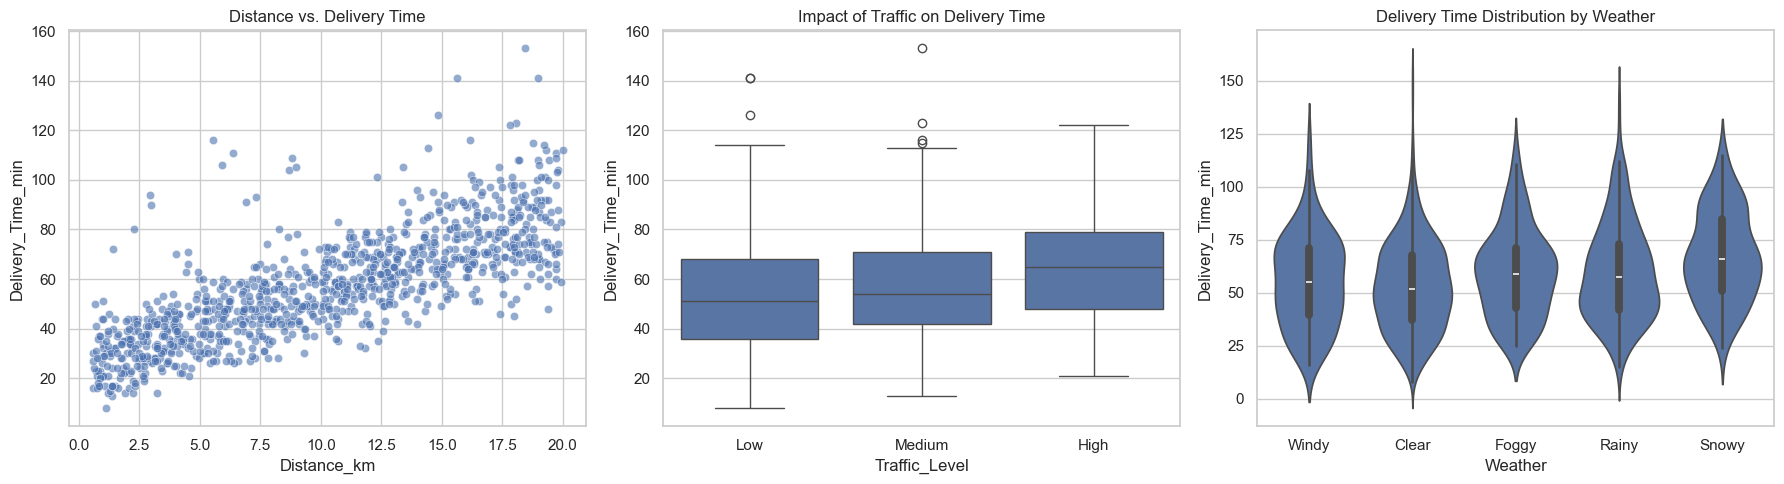

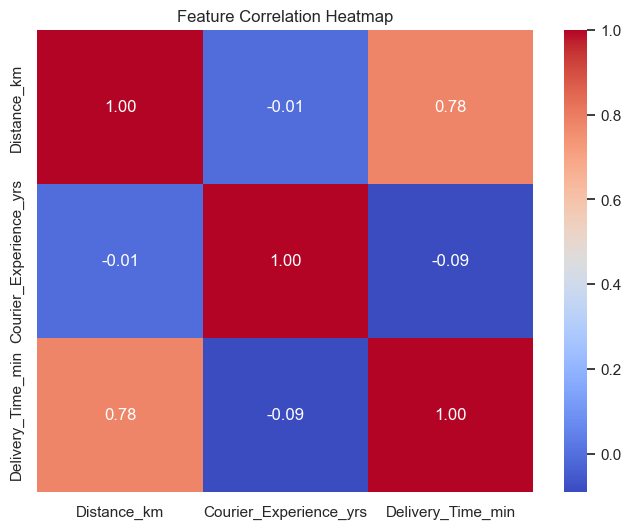

In [4]:
# Set visualization style
sns.set_theme(style="whitegrid")

# Create a figure with subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Distance vs. Delivery Time (Scatter Plot)
# Insight: There is a strong positive correlation (0.78) between distance and time.
sns.scatterplot(data=df, x='Distance_km', y='Delivery_Time_min', alpha=0.6, ax=axes[0])
axes[0].set_title('Distance vs. Delivery Time')

# Plot 2: Traffic Level Impact (Box Plot)
# Insight: High traffic averages ~64.8 minutes, while Low traffic averages ~52.8 minutes.
sns.boxplot(data=df, x='Traffic_Level', y='Delivery_Time_min', order=['Low', 'Medium', 'High'], ax=axes[1])
axes[1].set_title('Impact of Traffic on Delivery Time')

# Plot 3: Weather Conditions Impact (Violin Plot)
sns.violinplot(data=df, x='Weather', y='Delivery_Time_min', ax=axes[2])
axes[2].set_title('Delivery Time Distribution by Weather')

plt.tight_layout()
plt.show()

# Generate a Correlation Heatmap for numerical features
plt.figure(figsize=(8, 6))
numeric_cols = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Feature Correlation Heatmap')
plt.show()

In [5]:
df

,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Courier_Experience_yrs,Delivery_Time_min
0,7.93,Windy,Low,Afternoon,Scooter,1.0,43
1,16.42,Clear,Medium,Evening,Bike,2.0,84
2,9.52,Foggy,Low,Night,Scooter,1.0,59
3,7.44,Rainy,Medium,Afternoon,Scooter,1.0,37
4,19.03,Clear,Low,Morning,Bike,5.0,68
...,...,...,...,...,...,...,...
995,8.50,Clear,High,Evening,Car,3.0,54
996,16.28,Rainy,Low,Morning,Scooter,9.0,71
997,15.62,Snowy,High,Evening,Scooter,2.0,81
998,14.17,Clear,Low,Afternoon,Bike,0.0,55


In [6]:
df["Weather"].unique()

array(['Windy', 'Clear', 'Foggy', 'Rainy', 'Snowy'], dtype=object)

In [7]:
# encode manually
df["Weather"] = df["Weather"].map({"Windy":0, "Clear":1, "Foggy":2 , "Rainy":3 , "Snowy":4  })

In [8]:
df["Traffic_Level"].unique()

array(['Low', 'Medium', 'High'], dtype=object)

In [9]:
# encode manually
df["Traffic_Level"] = df["Traffic_Level"].map({"Low":0, "Medium":1, "High":2})

In [10]:
df["Time_of_Day"].unique()

array(['Afternoon', 'Evening', 'Night', 'Morning'], dtype=object)

In [11]:
# encode manually
df["Time_of_Day"] = df["Time_of_Day"].map({"Afternoon":0, "Evening":1, "Night":2 , "Morning":3})

In [12]:
df["Vehicle_Type"].unique()

array(['Scooter', 'Bike', 'Car'], dtype=object)

In [13]:
# encode manually
df["Vehicle_Type"] = df["Vehicle_Type"].map({"Scooter":0, "Bike":1, "Car":2})

In [14]:
df

,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Courier_Experience_yrs,Delivery_Time_min
0,7.93,0,0,0,0,1.0,43
1,16.42,1,1,1,1,2.0,84
2,9.52,2,0,2,0,1.0,59
3,7.44,3,1,0,0,1.0,37
4,19.03,1,0,3,1,5.0,68
...,...,...,...,...,...,...,...
995,8.50,1,2,1,2,3.0,54
996,16.28,3,0,3,0,9.0,71
997,15.62,4,2,1,0,2.0,81
998,14.17,1,0,0,1,0.0,55


In [6]:
# # 2. One-Hot Encoding for Categorical Variables
# # This converts text like "Rainy" into 0s and 1s so the model can read it
# df_encoded = pd.get_dummies(df, columns=['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type'], drop_first=True , dtype=int)



In [7]:
# df_encoded

,Distance_km,Courier_Experience_yrs,Delivery_Time_min,Weather_Foggy,Weather_Rainy,Weather_Snowy,Weather_Windy,Traffic_Level_Low,Traffic_Level_Medium,Time_of_Day_Evening,Time_of_Day_Morning,Time_of_Day_Night,Vehicle_Type_Car,Vehicle_Type_Scooter
0,7.93,1.0,43,0,0,0,1,1,0,0,0,0,0,1
1,16.42,2.0,84,0,0,0,0,0,1,1,0,0,0,0
2,9.52,1.0,59,1,0,0,0,1,0,0,0,1,0,1
3,7.44,1.0,37,0,1,0,0,0,1,0,0,0,0,1
4,19.03,5.0,68,0,0,0,0,1,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,8.50,3.0,54,0,0,0,0,0,0,1,0,0,1,0
996,16.28,9.0,71,0,1,0,0,1,0,0,1,0,0,1
997,15.62,2.0,81,0,0,1,0,0,0,1,0,0,0,1
998,14.17,0.0,55,0,0,0,0,1,0,0,0,0,0,0


In [8]:
# df_encoded.dtypes

Distance_km               float64
Courier_Experience_yrs    float64
Delivery_Time_min           int64
Weather_Foggy               int64
Weather_Rainy               int64
Weather_Snowy               int64
Weather_Windy               int64
Traffic_Level_Low           int64
Traffic_Level_Medium        int64
Time_of_Day_Evening         int64
Time_of_Day_Morning         int64
Time_of_Day_Night           int64
Vehicle_Type_Car            int64
Vehicle_Type_Scooter        int64
dtype: object

In [15]:
# 3. Define Features (X) and Target (y)
X = df.drop('Delivery_Time_min', axis=1)
X.head()

,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Courier_Experience_yrs
0,7.93,0,0,0,0,1.0
1,16.42,1,1,1,1,2.0
2,9.52,2,0,2,0,1.0
3,7.44,3,1,0,0,1.0
4,19.03,1,0,3,1,5.0


In [16]:
y = df['Delivery_Time_min']
y.head()

0    43
1    84
2    59
3    37
4    68
Name: Delivery_Time_min, dtype: int64

In [17]:
# 4. Train-Test Split (80% for training, 20% for testing)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(f"Training Data Shape: {X_train.shape}")
print(f"Testing Data Shape: {X_test.shape}")

Training Data Shape: (800, 6)
Testing Data Shape: (200, 6)


In [18]:
X_train.head()

,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Courier_Experience_yrs
29,18.05,1,1,1,0,7.0
535,2.14,1,2,1,1,3.0
695,3.23,1,2,0,1,9.0
557,7.51,3,0,1,2,6.0
836,4.62,3,1,0,2,3.0


In [19]:
print("The training input shape:", X_train.shape)
print("The training output shape:", y_train.shape)

print("The testing input shape:", X_test.shape)
print("The testing output shape:", y_test.shape)

The training input shape: (800, 6)
The training output shape: (800,)
The testing input shape: (200, 6)
The testing output shape: (200,)


In [20]:
# 5. Feature Selection / Importance (Using a base Random Forest)

from sklearn.ensemble import RandomForestRegressor
rf_selector = RandomForestRegressor(random_state=42)
rf_selector

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [21]:
rf_selector.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [22]:
y_pred = rf_selector.predict(X_test)
print(y_pred)

[37.42 64.2  39.51 34.26 80.11 27.71 63.43 43.75 36.56 79.57 77.21 58.66
 36.44 74.84 92.19 77.43 37.03 61.02 68.44 68.26 66.65 26.53 93.71 84.78
 61.24 36.2  90.37 21.48 49.96 53.69 70.4  26.18 75.74 29.75 65.53 32.52
 59.96 48.27 56.83 81.75 63.37 21.71 89.53 57.89 49.09 25.03 81.68 79.78
 79.68 36.52 73.03 70.7  50.25 77.9  42.56 66.47 77.11 95.37 63.95 80.74
 37.62 43.13 49.62 48.29 44.8  53.14 43.89 89.51 82.77 61.14 74.27 22.45
 82.47 28.7  59.44 72.5  52.3  48.76 48.24 36.2  68.94 58.38 72.77 37.39
 35.61 63.86 64.43 69.44 45.49 87.38 58.61 60.13 55.1  44.77 68.71 75.16
 50.62 47.36 41.13 43.28 28.48 55.4  38.68 37.25 41.98 25.85 51.18 22.69
 78.98 25.96 76.86 52.74 67.51 44.28 77.9  21.38 49.69 92.43 37.07 44.7
 50.83 90.09 71.15 73.59 53.18 55.57 39.15 57.41 53.1  41.4  47.02 53.48
 69.85 61.82 59.7  52.22 75.03 70.56 69.39 49.08 38.07 44.94 90.13 59.24
 56.01 74.87 81.05 54.22 69.51 35.87 54.18 53.84 65.85 93.53 42.22 29.86
 47.12 37.48 74.58 61.81 69.36 70.36 73.28 46.61 38.

In [23]:
from sklearn.metrics import root_mean_squared_error
root_mean_squared_error(y_test, y_pred)

12.118866366125175

In [24]:
from sklearn.metrics import accuracy_score

In [25]:
## KNN Regressor

from sklearn.neighbors import KNeighborsRegressor
knn = KNeighborsRegressor()
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)
print(y_pred)
root_mean_squared_error(y_test, y_pred)
#accuracy_score(y_test,y_pred)

[ 36.8  60.   37.   29.8  76.2  25.6  56.4  46.4  39.2  72.2  76.8  65.6
  38.4  77.8  77.2  75.6  33.4  45.2  59.8  64.6  68.2  28.4  95.4  90.6
  60.2  35.2  86.2  19.4  53.8  59.4  64.2  26.  104.4  33.4  65.   30.2
  60.   45.6  55.2  84.8  65.6  28.2  83.   50.8  47.6  27.   80.   67.2
  81.8  38.   50.8  62.   47.8  80.2  41.4  64.6  70.6  81.2  53.6  89.6
  37.2  45.4  45.   53.   39.6  59.6  49.8 102.6  74.4  53.8  71.4  25.4
  91.6  26.   64.2  68.4  52.4  46.4  44.2  33.6  65.   59.6  66.8  35.8
  43.2  72.   71.6  73.2  47.2  80.8  53.4  56.4  57.6  49.6  75.   80.2
  55.6  47.4  35.4  50.6  36.2  60.8  34.8  34.6  38.6  23.4  51.4  31.6
  80.2  47.   70.8  55.   65.   44.4  93.4  39.6  62.   63.4  34.6  53.8
  58.  104.6  68.8  88.2  65.6  65.6  36.2  64.   67.   33.8  44.4  54.8
  69.2  57.2  60.   55.6  79.   68.2  69.   47.6  39.8  37.8  78.   62.8
  50.6  69.6  95.   59.   75.8  28.8  60.4  47.4  68.6  88.6  44.   35.
  52.4  41.6  72.6  69.   68.6  66.6  61.4  45.4  34

13.309357610343183

In [26]:
from sklearn.tree import DecisionTreeRegressor
dt = DecisionTreeRegressor()
dt.fit(X_train, y_train)
y_pred = dt.predict(X_test)
print(y_pred)
root_mean_squared_error(y_test, y_pred)
#accuracy_score(y_test , y_pred)

[ 57.  71.  25.  32.  92.  21.  62.  43.  27.  85.  78.  75.  34.  75.
  88.  71.  27.  57.  43.  69.  56.  31. 103.  71.  65.  27.  81.  13.
  51.  40.  74.  30.  83.  41.  71.  28.  58.  40.  67.  97.  53.  31.
 103.  57.  34.  32.  97. 116.  62.  26. 116.  82.  52.  99.  46.  65.
  90. 141.  56. 108.  28.  44. 116.  59.  51.  59.  42. 103.  95.  58.
  71.  29. 108.  29.  51. 101.  80.  47.  46.  45.  71.  62.  78.  25.
  30.  59.  65.  66.  35.  71.  56.  36.  30.  27.  89.  62.  56.  55.
  44.  36.  27.  58.  35.  27.  43.  39.  47.  17.  71.  19.  80.  51.
  65.  33.  68.  19.  41.  61.  27.  40.  42.  67.  48.  85.  55.  43.
  45.  49.  55.  46.  48.  58.  69.  39.  48.  71.  84.  84.  58.  51.
  42.  51.  92.  61.  73.  64.  67.  45.  46.  40.  37.  56.  66. 141.
  35.  25.  78.  37.  83.  60.  64.  83.  54.  51.  35.  84.  46.  70.
  44.  84.  49.  28.  25.  31.  13.  64.  70.  46.  95.  97.  61.  38.
  68.  70.  80.  37.  51.  46.  73.  32.  74.  28.  43.  44.  42.  51.
  24. 

18.661457606521523

In [27]:
# linear regression

from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)
print(y_pred)
root_mean_squared_error(y_test, y_pred)
#accuracy_score(y_test , y_pred)

[36.40651229 58.96106264 47.83087375 37.67616451 77.34870347 25.61595283
 63.78095376 40.16395481 43.27183831 82.12543511 68.6557991  57.84763931
 38.99906947 75.69600119 82.58327864 72.34567846 35.93013208 57.62259639
 60.01609678 65.02935278 75.95861172 31.32494471 92.3258592  82.35224806
 70.26799809 39.42987763 89.72206381 28.42900561 48.85873472 60.48553968
 70.39611472 25.91645705 70.89912634 31.29372167 60.78340837 32.36329277
 54.32296469 55.85104757 58.34027631 83.34877738 66.35298315 24.22773149
 89.28578757 58.66584783 40.30204912 25.98397548 83.09221525 74.17447695
 76.84217207 35.02814371 53.80578037 62.34591031 44.71269389 75.82788911
 46.59470692 63.22113732 76.65791846 85.72592059 56.86502656 81.66064923
 38.15395594 39.51075298 50.68887863 56.16317925 50.32063217 57.98223592
 54.27844735 91.80906915 88.16286608 56.46462807 81.34499735 31.18923305
 83.64131345 26.287257   58.74008207 68.43047516 47.97877245 49.63621974
 45.34963935 41.25634601 65.33749254 55.2013379  65

11.366449314731858

In [28]:
df


,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Courier_Experience_yrs,Delivery_Time_min
0,7.93,0,0,0,0,1.0,43
1,16.42,1,1,1,1,2.0,84
2,9.52,2,0,2,0,1.0,59
3,7.44,3,1,0,0,1.0,37
4,19.03,1,0,3,1,5.0,68
...,...,...,...,...,...,...,...
995,8.50,1,2,1,2,3.0,54
996,16.28,3,0,3,0,9.0,71
997,15.62,4,2,1,0,2.0,81
998,14.17,1,0,0,1,0.0,55


In [29]:
Distance_km = 10
Weather = 1	
Traffic_Level = 2	
Time_of_Day = 3
Vehicle_Type = 2
Courier_Experience_yrs = 1 



lr.predict([[Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Courier_Experience_yrs]])[0]

np.float64(65.17377681216163)

In [30]:
import pickle

In [31]:
with open(r"model.pkl",'wb') as file:
    pickle.dump(lr, file)

# pickle.dump() = trained model is saved into model.pkl

In [32]:
with open(r"model.pkl","rb") as file:
    model = pickle.load(file)

model

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [34]:
def Prediction(Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Courier_Experience_yrs):
    return model.predict([[Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Courier_Experience_yrs]])[0]

In [35]:
Prediction

<function __main__.Prediction(Distance_km, Weather, Traffic_Level, Time_of_Day, Vehicle_Type, Courier_Experience_yrs)>

In [36]:
pip install gradio

Note: you may need to restart the kernel to use updated packages.


In [37]:
import gradio as gr

In [40]:
# iface = gr.Interface(fn = Prediction,
#                     title = "del_time Prediction",
#                     outputs = gr.Textbox(label = "Predicted Price"),
#                     inputs = [
#                             gr.Number(label="Distance (km)"),
#                             gr.Dropdown(["Windy", "Clear", "Foggy", "Rainy", "Snowy"]),
#                             gr.Dropdown(["Low", "Medium", "High"]),
#                             gr.Dropdown(["Afternoon", "Evening", "Night", "Morning"]),
#                             gr.Dropdown(["Scooter", "Bike", "Car"]),
#                             gr.Number(label="Courier Experience (years)")
#                     ] 
#                     )

In [43]:
iface = gr.Interface(fn = Prediction,
                    title = "del_time Prediction",
                    outputs = gr.Textbox(label = "Predicted Price"),
                    inputs = [
                            gr.Number(label = "Distance"),
                            gr.Number(label = "Weather"),
                            gr.Number(label = "Traffic_Level"),
                            gr.Number(label = "Time_of_Day"),
                            gr.Number(label = "Vehicle_Type"),
                            gr.Number(label = "Courier_Experience_yrs"),
                    ] 
                    )

In [42]:
df

,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Courier_Experience_yrs,Delivery_Time_min
0,7.93,0,0,0,0,1.0,43
1,16.42,1,1,1,1,2.0,84
2,9.52,2,0,2,0,1.0,59
3,7.44,3,1,0,0,1.0,37
4,19.03,1,0,3,1,5.0,68
...,...,...,...,...,...,...,...
995,8.50,1,2,1,2,3.0,54
996,16.28,3,0,3,0,9.0,71
997,15.62,4,2,1,0,2.0,81
998,14.17,1,0,0,1,0.0,55


In [46]:
iface.launch(share = True)

* Running on local URL:  http://127.0.0.1:7863
* Running on public URL: https://59d8b16d4e87f5fb12.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
